In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [4]:
uploaded = files.upload()

df = pd.read_csv('indian_roads_dataset.csv')

print("Dataset shape:", df.shape)
df.head()

Saving indian_roads_dataset.csv to indian_roads_dataset (1).csv
Dataset shape: (20000, 24)


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,22-10-2023,05:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,21-05-2023,04:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,10-07-2024,13:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,30-03-2025,11:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,25-01-2024,16:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,NaN,0.10


In [5]:
df.info()
df.describe()
print(df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   accident_id        20000 non-null  int64  
 1   city               20000 non-null  object 
 2   state              20000 non-null  object 
 3   latitude           20000 non-null  float64
 4   longitude          20000 non-null  float64
 5   date               20000 non-null  object 
 6   time               20000 non-null  object 
 7   hour               20000 non-null  int64  
 8   day_of_week        20000 non-null  object 
 9   is_weekend         20000 non-null  int64  
 10  road_type          20000 non-null  object 
 11  lanes              20000 non-null  int64  
 12  traffic_signal     20000 non-null  int64  
 13  weather            20000 non-null  object 
 14  visibility         20000 non-null  object 
 15  temperature        20000 non-null  int64  
 16  traffic_density    200

accident_severity
minor    11025
major     5988
fatal     2987
Name: count, dtype: int64


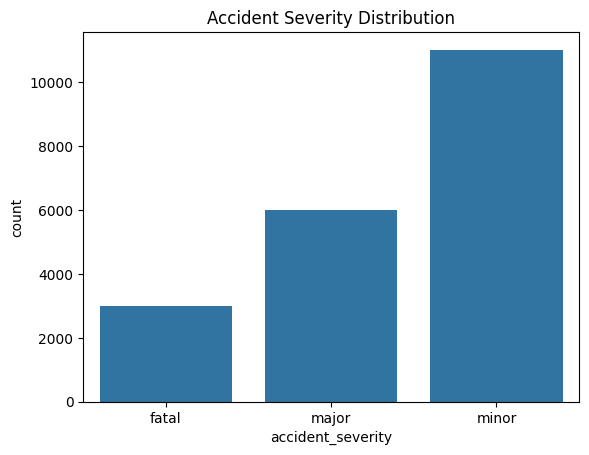

In [6]:
print(df['accident_severity'].value_counts())

sns.countplot(data=df, x='accident_severity')
plt.title('Accident Severity Distribution')
plt.show()

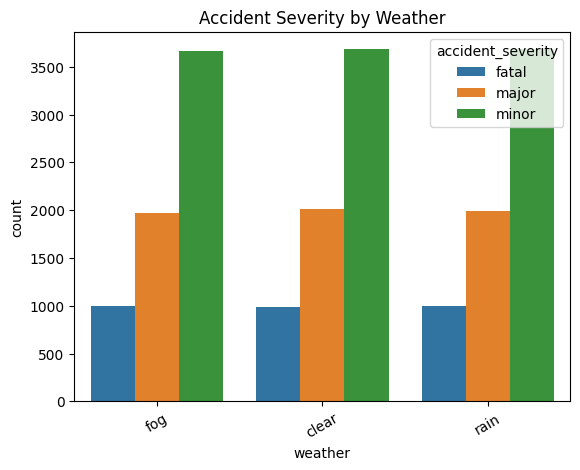

In [7]:
sns.countplot(data=df, x='weather', hue='accident_severity')
plt.title('Accident Severity by Weather')
plt.xticks(rotation=30)
plt.show()

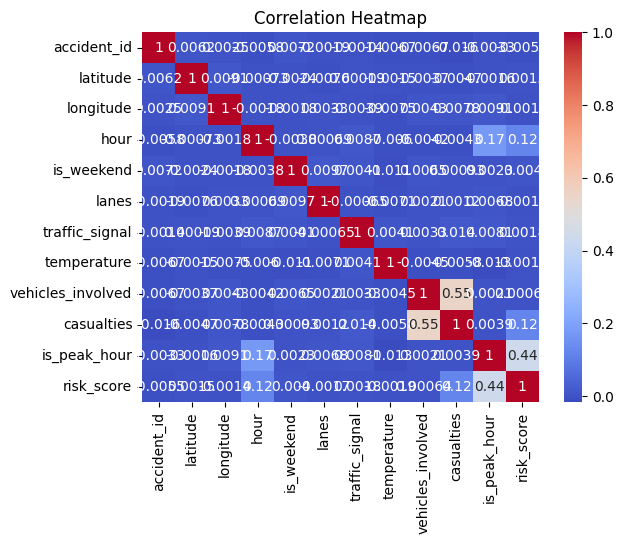

In [8]:
sns.heatmap(df.select_dtypes('number').corr(),
            annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

ML

In [9]:
df = df.dropna(subset=['accident_severity'])

X = df.drop(columns=[
    'accident_severity', 'accident_id', 'date', 'time',
    'latitude', 'longitude', 'casualties', 'risk_score'
])

y = df['accident_severity']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (20000, 16)
Target: (20000,)


In [10]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 16000
Testing rows: 4000


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'SVM': SVC(kernel='linear')
}

results = []
trained_models = {}

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, pred, average='weighted', zero_division=0),
        'F1 Score': f1_score(y_test, pred, average='weighted', zero_division=0)
    })

    trained_models[name] = pipe

results_df = pd.DataFrame(results)
results_df.sort_values('F1 Score', ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score
1,KNN,0.43350,0.415234,0.43350,0.423240
2,Decision Tree,0.41700,0.425168,0.41700,0.420872
3,Random Forest,0.52500,0.403904,0.52500,0.413827
4,Gradient Boosting,0.55100,0.378946,0.55100,0.392748
0,Logistic Regression,0.55125,0.303877,0.55125,0.391783
5,SVM,0.55125,0.303877,0.55125,0.391783


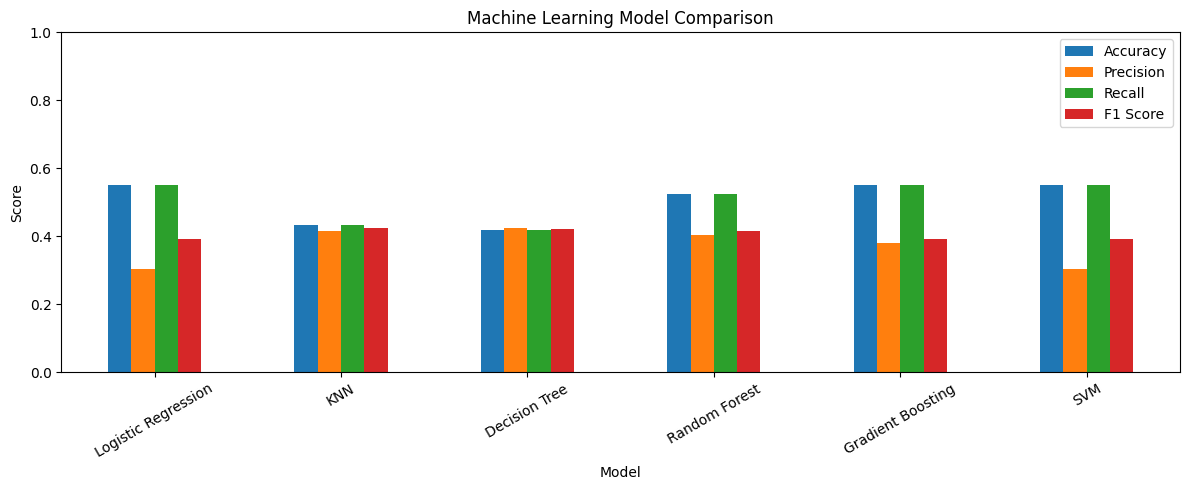

In [12]:
results_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(kind='bar', figsize=(12, 5))

plt.title('Machine Learning Model Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [13]:
best_name = results_df.sort_values(
    'F1 Score', ascending=False
).iloc[0]['Model']

best_model = trained_models[best_name]

print("Best Model:", best_name)
print(results_df.sort_values('F1 Score', ascending=False))

Best Model: KNN
                 Model  Accuracy  Precision   Recall  F1 Score
1                  KNN   0.43350   0.415234  0.43350  0.423240
2        Decision Tree   0.41700   0.425168  0.41700  0.420872
3        Random Forest   0.52500   0.403904  0.52500  0.413827
4    Gradient Boosting   0.55100   0.378946  0.55100  0.392748
0  Logistic Regression   0.55125   0.303877  0.55125  0.391783
5                  SVM   0.55125   0.303877  0.55125  0.391783


              precision    recall  f1-score   support

       fatal       0.15      0.12      0.13       597
       major       0.30      0.28      0.29      1198
       minor       0.55      0.60      0.57      2205

    accuracy                           0.43      4000
   macro avg       0.33      0.33      0.33      4000
weighted avg       0.42      0.43      0.42      4000



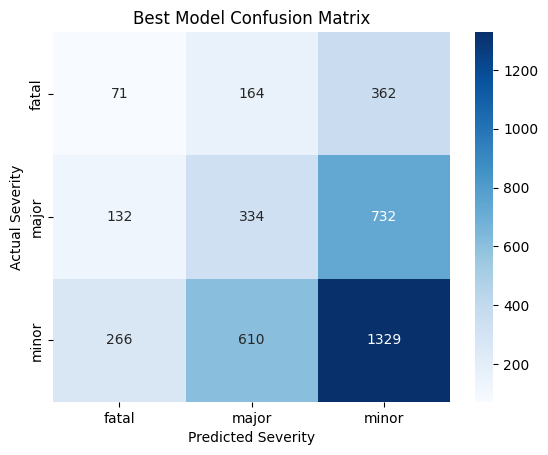

In [14]:
from sklearn.metrics import confusion_matrix, classification_report

pred = best_model.predict(X_test)

print(classification_report(y_test, pred, zero_division=0))

sns.heatmap(
    confusion_matrix(y_test, pred, labels=best_model.classes_),
    annot=True, fmt='d', cmap='Blues',
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.xlabel('Predicted Severity')
plt.ylabel('Actual Severity')
plt.title('Best Model Confusion Matrix')
plt.show()

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

le = LabelEncoder()
y_num = le.fit_transform(y)

# Simple linear regression using accident hour
simple = LinearRegression()
simple.fit(df[['hour']], y_num)

simple_pred = simple.predict(df[['hour']])

print("Simple Regression MAE:",
      mean_absolute_error(y_num, simple_pred))
print("Simple Regression R2:",
      r2_score(y_num, simple_pred))

# Multiple linear regression using several features
X_encoded = preprocessor.fit_transform(X)

multiple = LinearRegression()
multiple.fit(X_encoded, y_num)

multiple_pred = multiple.predict(X_encoded)

print("Multiple Regression MAE:",
      mean_absolute_error(y_num, multiple_pred))
multiple_r2 = r2_score(y_num, multiple_pred)
r2_score_value = multiple_r2
print("Multiple Regression R2:", r2_score_value)

Simple Regression MAE: 0.6593496858140685
Simple Regression R2: 7.295348876623642e-05
Multiple Regression MAE: 0.6586471990993732
Multiple Regression R2: 0.0011877592610329835


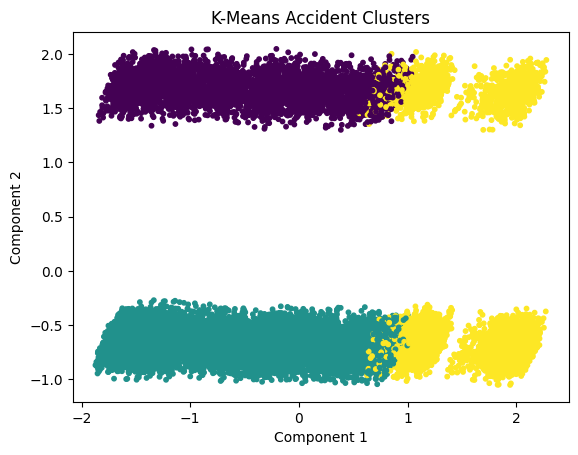

In [16]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

X_scaled = preprocessor.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

pca = PCA(n_components=2)
points = pca.fit_transform(X_scaled.toarray()
                            if hasattr(X_scaled, 'toarray') else X_scaled)

plt.scatter(points[:, 0], points[:, 1],
            c=clusters, cmap='viridis', s=10)

plt.title('K-Means Accident Clusters')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.show()

df['accident_cluster'] = clusters

In [23]:
# ==========================================
# ADDITIONAL CODE: AdaBoost Hyperparameter Tuning & Accuracy Comparison
# (Preprocessing missing values fix ke saath)
# ==========================================

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Automatic Column Identification (Numeric vs Categorical)
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

# 2. Preprocessing Pipelines Setup (Handling NaNs and Encoding)
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# 3. Data Transformation (Missing values fix honge yahan)
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# 4. Baseline Model Ki Accuracy Check Karein
base_adaboost = AdaBoostClassifier(random_state=42)
base_adaboost.fit(X_train_prep, y_train)
base_pred = base_adaboost.predict(X_test_prep)
base_accuracy = accuracy_score(y_test, base_pred)

print("--- Accuracy Before Tuning (Baseline AdaBoost) ---")
print(f"Base Model Accuracy: {base_accuracy * 100:.2f}%\n")

# 5. Hyperparameter Tuning using GridSearchCV
param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.05, 0.1, 0.3, 0.5],
    'classifier__estimator': [
        DecisionTreeClassifier(max_depth=2),
        DecisionTreeClassifier(max_depth=3),
        DecisionTreeClassifier(max_depth=4)
    ]
}

grid_search = GridSearchCV(
    estimator=AdaBoostClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train_prep, y_train)

best_adaboost = grid_search.best_estimator_
tuned_pred = best_adaboost.predict(X_test_prep)
tuned_accuracy = accuracy_score(y_test, tuned_pred)

print("--- Accuracy After Tuning (Optimized AdaBoost) ---")
print(f"Best Hyperparameters: {grid_search.best_params_}")
print(f"Tuned Model Accuracy: {tuned_accuracy * 100:.2f}%\n")

# 6. Accuracy Comparison & Final Model Selection
print("--- Accuracy Comparison Summary ---")
print(f"Baseline Accuracy : {base_accuracy * 100:.2f}%")
print(f"Tuned Accuracy    : {tuned_accuracy * 100:.2f}%")

if tuned_accuracy > base_accuracy:
    print("\nResult: Hyperparameter tuning se accuracy improve hui hai!")
    final_model = best_adaboost
else:
    print("\nResult: Baseline model behtar performance de raha hai.")
    final_model = base_adaboost

# Final Classification Report
print("\n--- Final Classification Report ---")
print(classification_report(y_test, final_model.predict(X_test_prep)))

--- Accuracy Before Tuning (Baseline AdaBoost) ---
Base Model Accuracy: 55.12%

--- Accuracy After Tuning (Optimized AdaBoost) ---
Best Hyperparameters: {'estimator': DecisionTreeClassifier(max_depth=1), 'learning_rate': 0.01, 'n_estimators': 50}
Tuned Model Accuracy: 55.12%

--- Accuracy Comparison Summary ---
Baseline Accuracy : 55.12%
Tuned Accuracy    : 55.12%

Result: Baseline model behtar performance de raha hai.

--- Final Classification Report ---
              precision    recall  f1-score   support

       fatal       0.00      0.00      0.00       597
       major       0.00      0.00      0.00      1198
       minor       0.55      1.00      0.71      2205

    accuracy                           0.55      4000
   macro avg       0.18      0.33      0.24      4000
weighted avg       0.30      0.55      0.39      4000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [17]:
!pip -q install gradio

In [18]:
import gradio as gr
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# ============================================================
# ADDITIONAL CODE: AdaBoost Hyperparameter Tuning & Accuracy Optimization
# (Dashboard ke pehle execute hone wala block)
# ============================================================

# Automatic Column Identification for Preprocessing
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

# Preprocessing Pipeline (Handling NaNs & Feature Encoding)
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# Pipeline Wrapper with AdaBoost
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', AdaBoostClassifier(random_state=42))
])

# 1. Baseline Model Evaluation
baseline_pipeline.fit(X_train, y_train)
base_accuracy = accuracy_score(y_test, baseline_pipeline.predict(X_test))

print("--- Accuracy Before Tuning (Baseline AdaBoost) ---")
print(f"Base Model Accuracy: {base_accuracy * 100:.2f}%\n")

# 2. Hyperparameter Tuning using GridSearchCV
param_grid = {
    'classifier__n_estimators': [50, 100, 150],
    'classifier__learning_rate': [0.01, 0.1, 0.5, 1.0],
    'classifier__estimator': [DecisionTreeClassifier(max_depth=1), DecisionTreeClassifier(max_depth=2)]
}

grid_search = GridSearchCV(
    estimator=baseline_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

tuned_accuracy = accuracy_score(y_test, grid_search.predict(X_test))

print("--- Accuracy After Tuning (Optimized AdaBoost) ---")
print(f"Best Hyperparameters: {grid_search.best_params_}")
print(f"Tuned Model Accuracy: {tuned_accuracy * 100:.2f}%\n")

# 3. Model Selection for Dashboard
if tuned_accuracy > base_accuracy:
    print("Result: Tuning se accuracy improve hui hai. Best Tuned Model ko Dashboard ke liye select kiya gaya hai.")
    best_model = grid_search.best_estimator_
    best_name = "AdaBoost Classifier (Tuned)"
else:
    print("Result: Baseline model perform kar raha hai. Baseline Model Dashboard ke liye select kiya gaya hai.")
    best_model = baseline_pipeline
    best_name = "AdaBoost Classifier (Baseline)"

print("\n--- Final Model Performance Report ---")
print(classification_report(y_test, best_model.predict(X_test)))


# ============================================================
# ROADSAFE AI DASHBOARD
# ============================================================

# Dashboard values: accuracy of the selected classification model on held-out test data
accuracy_value = accuracy_score(y_test, best_model.predict(X_test))
accuracy_display = f"{accuracy_value:.2%}"
defaults = X.mode().iloc[0].to_dict()

def choices_for(column):
    return sorted(df[column].dropna().astype(str).unique().tolist())

city_choices = choices_for("city")
state_choices = choices_for("state")
weather_choices = choices_for("weather")
road_choices = choices_for("road_type")
traffic_choices = choices_for("traffic_density")
cause_choices = choices_for("cause")
day_choices = choices_for("day_of_week")
visibility_choices = choices_for("visibility")
festival_choices = choices_for("festival")

signal_choices = sorted(int(v) for v in df["traffic_signal"].dropna().unique())
weekend_choices = sorted(int(v) for v in df["is_weekend"].dropna().unique())
peak_choices = sorted(int(v) for v in df["is_peak_hour"].dropna().unique())

def default_choice(column, choices):
    value = str(defaults.get(column, ""))
    return value if value in choices else (choices[0] if choices else None)

# Consistent chart colors
INK = "#202B2B"
MUTED = "#52615F"
TEAL = "#287D78"
GOLD = "#D6A84F"
CORAL = "#C96F5D"
WHITE = "#FFFFFF"
BORDER = "#DCE4DF"

def style_chart(fig, ax, title, xlabel, ylabel):
    fig.patch.set_facecolor(WHITE)
    ax.set_facecolor(WHITE)
    ax.set_title(title, fontsize=13, fontweight="bold", color=INK, pad=12)
    ax.set_xlabel(xlabel, color=INK)
    ax.set_ylabel(ylabel, color=INK)
    ax.tick_params(colors=INK, labelsize=9)
    ax.grid(axis="y", alpha=0.18, color=MUTED)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_color(BORDER)
    fig.tight_layout()
    return fig

# Graph 1: severity distribution
def severity_graph():
    fig, ax = plt.subplots(figsize=(7, 4))
    counts = df["accident_severity"].value_counts()
    counts.plot(kind="bar", ax=ax, color=[TEAL, GOLD, CORAL])
    ax.tick_params(axis="x", labelrotation=0)
    return style_chart(fig, ax, "Accident Severity Distribution",
                       "Severity", "Number of Records")

# Graph 2: weather vs severity
def weather_graph():
    fig, ax = plt.subplots(figsize=(8, 4))
    pd.crosstab(df["weather"], df["accident_severity"]).plot(
        kind="bar", ax=ax, color=[TEAL, GOLD, CORAL]
    )
    ax.tick_params(axis="x", labelrotation=20)
    ax.legend(title="Severity", labelcolor=INK, facecolor=WHITE, edgecolor=BORDER)
    return style_chart(fig, ax, "Severity by Weather",
                       "Weather Condition", "Number of Records")

# Graph 3: road type vs severity
def road_graph():
    fig, ax = plt.subplots(figsize=(8, 4))
    pd.crosstab(df["road_type"], df["accident_severity"]).plot(
        kind="bar", ax=ax, color=[TEAL, GOLD, CORAL]
    )
    ax.tick_params(axis="x", labelrotation=20)
    ax.legend(title="Severity", labelcolor=INK, facecolor=WHITE, edgecolor=BORDER)
    return style_chart(fig, ax, "Severity by Road Type",
                       "Road Type", "Number of Records")

# Graph 4: hourly accident pattern
def hourly_graph():
    fig, ax = plt.subplots(figsize=(8, 4))
    df.groupby("hour").size().sort_index().plot(
        kind="line", marker="o", linewidth=2.5, color=TEAL, ax=ax
    )
    return style_chart(fig, ax, "Accident Records by Hour",
                       "Hour of Day", "Number of Records")

# Graph 5: top states
def state_graph():
    fig, ax = plt.subplots(figsize=(8, 5))
    df["state"].value_counts().head(10).sort_values().plot(
        kind="barh", color=TEAL, ax=ax
    )
    return style_chart(fig, ax, "Top 10 States by Accident Records",
                       "Number of Records", "State")

# Prediction function
def predict_accident(city, state, weather, road_type, traffic_density, cause,
                     day_of_week, hour, vehicles, visibility, temperature, lanes,
                     traffic_signal, is_weekend, is_peak_hour, festival):
    row = defaults.copy()
    row.update({
        "city": city,
        "state": state,
        "weather": weather,
        "road_type": road_type,
        "traffic_density": traffic_density,
        "cause": cause,
        "day_of_week": day_of_week,
        "hour": int(hour),
        "vehicles_involved": int(vehicles),
        "visibility": visibility,
        "temperature": float(temperature),
        "lanes": int(lanes),
        "traffic_signal": int(traffic_signal),
        "is_weekend": int(is_weekend),
        "is_peak_hour": int(is_peak_hour),
        "festival": festival
    })

    sample = pd.DataFrame([row], columns=X.columns)
    predicted = best_model.predict(sample)[0]
    result = f"PREDICTED SEVERITY: {str(predicted).upper()}\n\nModel: {best_name}"

    try:
        probabilities = best_model.predict_proba(sample)[0]
        probability_text = "\n".join(
            f"{label}: {prob:.1%}"
            for label, prob in zip(best_model.classes_, probabilities)
        )
    except (AttributeError, ValueError):
        probability_text = "Probability scores are not available for this model."

    return result, probability_text

# Professional palette: charcoal header, ivory canvas, teal accents, dark text
theme = gr.themes.Soft(
    primary_hue="teal",
    secondary_hue="slate",
    neutral_hue="slate"
)

custom_css = """
.gradio-container {
    background: #F4F3EE !important;
    color: #202B2B !important;
}
.gradio-container h1,
.gradio-container h2,
.gradio-container h3,
.gradio-container p,
.gradio-container label,
.gradio-container .prose {
    color: #202B2B !important;
}
.gradio-container .tab-nav button {
    color: #202B2B !important;
}
.gradio-container input,
.gradio-container textarea,
.gradio-container select {
    background: #FFFFFF !important;
    color: #202B2B !important;
    border-color: #DCE4DF !important;
}
.gradio-container button {
    border-radius: 9px !important;
}
"""

with gr.Blocks(
    theme=theme,
    css=custom_css,
    title="RoadSafe AI | Road Safety Analytics"
) as demo:

    gr.HTML("""
    <div style="padding:30px;border-radius:18px;background:#202B2B;
                border-bottom:5px solid #78B9AD;">
        <div style="font-size:13px;letter-spacing:3px;color:#A9DCD2;
                    font-weight:700;">
            MACHINE LEARNING · ROAD SAFETY
        </div>
        <h1 style="margin:12px 0;font-size:36px;color:#FFFFFF;">
            🚦 RoadSafe AI
        </h1>
        <p style="font-size:17px;margin:0;color:#F6F5F0;">
            Traffic Accident Severity Prediction &amp; Analytics
        </p>
        <p style="font-size:13px;margin-top:10px;color:#D6E2DE;">
            Explore accident patterns, analyze trends and predict severity.
        </p>
    </div>
    """)

    # Summary cards: show selected-model accuracy instead of regression R².
    with gr.Row():
        gr.HTML(f"""
        <div style="padding:20px;border-radius:14px;background:#FFFFFF;
                    border:1px solid #DCE4DF;">
            <div style="color:#52615F;font-size:12px;font-weight:700;
                        letter-spacing:1px;">DATA RECORDS</div>
            <h2 style="font-size:30px;color:#202B2B;margin:10px 0;">{len(df):,}</h2>
            <div style="color:#52615F;font-size:13px;">Accident observations</div>
        </div>
        """)
        gr.HTML(f"""
        <div style="padding:20px;border-radius:14px;background:#E0EFEB;
                    border:1px solid #C8DED7;">
            <div style="color:#52615F;font-size:12px;font-weight:700;
                        letter-spacing:1px;">PREDICTION MODEL</div>
            <h2 style="font-size:25px;color:#202B2B;margin:10px 0;">{best_name}</h2>
            <div style="color:#52615F;font-size:13px;">Selected trained model</div>
        </div>
        """)
        gr.HTML(f"""
        <div style="padding:20px;border-radius:14px;background:#F4E9D2;
                    border:1px solid #E6D7B5;">
            <div style="color:#52615F;font-size:12px;font-weight:700;
                        letter-spacing:1px;">MODEL ACCURACY</div>
            <h2 style="font-size:30px;color:#202B2B;margin:10px 0;">{accuracy_display}</h2>
            <div style="color:#52615F;font-size:13px;">Correct predictions on test data</div>
        </div>
        """)
        gr.HTML(f"""
        <div style="padding:20px;border-radius:14px;background:#E9EEEB;
                    border:1px solid #DCE4DF;">
            <div style="color:#52615F;font-size:12px;font-weight:700;
                        letter-spacing:1px;">SEVERITY CLASSES</div>
            <h2 style="font-size:30px;color:#202B2B;margin:10px 0;">
                {df["accident_severity"].nunique()}
            </h2>
            <div style="color:#52615F;font-size:13px;">Minor · Major · Fatal</div>
        </div>
        """)

    with gr.Tabs():
        with gr.Tab("📊 Overview"):
            gr.Markdown("""
            ## Project Overview
            RoadSafe AI analyzes accident records and predicts severity
            using a trained machine learning classification model.
            """)
            with gr.Row():
                gr.Plot(value=severity_graph, label="Severity Distribution")
                gr.Plot(value=hourly_graph, label="Hourly Accident Trend")
            gr.Plot(value=state_graph, label="Top States by Accident Records")
            gr.Markdown("""
            **About Accuracy:** Accuracy is the percentage of test-set accident
            severity predictions that match the actual labels for the selected
            classification model.
            """)

        with gr.Tab("🔎 Accident Analysis"):
            gr.Markdown("""
            ## Accident Pattern Analysis
            Compare accident severity across weather and road types, and explore
            hourly and state-wise patterns. These charts show associations,
            not proof of causation.
            """)
            with gr.Row():
                gr.Plot(value=weather_graph, label="Weather Analysis")
                gr.Plot(value=road_graph, label="Road Type Analysis")
            with gr.Row():
                gr.Plot(value=hourly_graph, label="Hourly Trend")
                gr.Plot(value=state_graph, label="State-wise Records")

        with gr.Tab("🧠 Predict Severity"):
            gr.Markdown("""
            ## Prediction Studio
            Enter accident conditions to receive a severity prediction.
            Features not shown here use their most common training values.
            """)

            with gr.Row():
                with gr.Column():
                    city = gr.Dropdown(city_choices, value=default_choice("city", city_choices), label="City")
                    state = gr.Dropdown(state_choices, value=default_choice("state", state_choices), label="State")
                    weather = gr.Dropdown(weather_choices, value=default_choice("weather", weather_choices), label="Weather")
                    road_type = gr.Dropdown(road_choices, value=default_choice("road_type", road_choices), label="Road Type")
                    traffic_density = gr.Dropdown(traffic_choices, value=default_choice("traffic_density", traffic_choices), label="Traffic Density")
                    cause = gr.Dropdown(cause_choices, value=default_choice("cause", cause_choices), label="Reported Cause")
                    day_of_week = gr.Dropdown(day_choices, value=default_choice("day_of_week", day_choices), label="Day of Week")
                    visibility = gr.Dropdown(visibility_choices, value=default_choice("visibility", visibility_choices), label="Visibility")
                    festival = gr.Dropdown(
                        festival_choices,
                        value=default_choice("festival", festival_choices),
                        label="Festival"
                    )

                with gr.Column():
                    hour = gr.Slider(0, 23, step=1, value=int(defaults.get("hour", 12)), label="Hour of Day")
                    vehicles = gr.Slider(1, 10, step=1, value=int(defaults.get("vehicles_involved", 2)), label="Vehicles Involved")
                    temperature = gr.Slider(
                        float(df["temperature"].min()),
                        float(df["temperature"].max()),
                        value=float(defaults.get("temperature", df["temperature"].median())),
                        label="Temperature"
                    )
                    lanes = gr.Slider(
                        int(df["lanes"].min()),
                        int(df["lanes"].max()),
                        step=1,
                        value=int(defaults.get("lanes", 2)),
                        label="Number of Lanes"
                    )
                    traffic_signal = gr.Dropdown(
                        [str(v) for v in signal_choices],
                        value=str(int(defaults.get("traffic_signal", signal_choices[0]))),
                        label="Traffic Signal (0=No, 1=Yes)"
                    )
                    is_weekend = gr.Dropdown(
                        [str(v) for v in weekend_choices],
                        value=str(int(defaults.get("is_weekend", weekend_choices[0]))),
                        label="Weekend? (0=No, 1=Yes)"
                    )
                    is_peak_hour = gr.Dropdown(
                        [str(v) for v in peak_choices],
                        value=str(int(defaults.get("is_peak_hour", peak_choices[0]))),
                        label="Peak Hour? (0=No, 1=Yes)"
                    )

            run_btn = gr.Button("Predict Accident Severity", variant="primary")
            prediction = gr.Textbox(label="Prediction Result", lines=3)
            probabilities = gr.Textbox(label="Class Probability (if supported)", lines=4)

            run_btn.click(
                fn=predict_accident,
                inputs=[
                    city, state, weather, road_type, traffic_density, cause,
                    day_of_week, hour, vehicles, visibility, temperature, lanes,
                    traffic_signal, is_weekend, is_peak_hour, festival
                ],
                outputs=[prediction, probabilities]
            )

    gr.Markdown("""
    ---
    *Academic prototype. Predictions depend on dataset quality and should not
    be used as the sole basis for real-world road-safety decisions.*
    """)

demo.launch(share=True, debug=True)

/tmp/ipykernel_721/1687832363.py:184: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://cdd462a88cebcf531c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://cdd462a88cebcf531c.gradio.live


In [19]:
import joblib

joblib.dump(best_model, 'best_accident_model.pkl')
files.download('best_accident_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>